# salt_fountain1: salt fountain in a pipe with heat conducting walls
pyOM2: for_config/salt_fountain1.f90

Non-hydrostatic x-z slice (nh_realistic). Warm salty water lies above cold
fresh water of the same density. A vertical wall (land cells inside the water
column) separates the pipe on the left from the right part of the domain.
Heat is conducted through the wall, salt is not, so the fresh water lifted
into the pipe is warmed and keeps rising.

In [1]:
import sys; sys.path.append('../..')
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output
import pyOM3 as OM
from pyOM3.nh_realistic.model import model
from pyOM3.density import linear_eq_of_state_drhodT, linear_eq_of_state_drhodS

found mpi4py
Jax not available


In [2]:
fac        = 2.0
nx, ny, nz = int(32*fac), 1, int(32*fac)
dx = dz    = 0.5/fac
dt         = 0.25/fac
visc       = 4e-3/fac**2
kappa_pipe = 5e-3                     # heat conduction through the wall
Tm, Sm     = 10., 34.                 # cold fresh water
Tp         = Tm - 0.5/linear_eq_of_state_drhodT()    # warm salty water,
Sp         = Sm + 0.5/linear_eq_of_state_drhodS()    # same density
i_pipe     = nx//3 - 1                # x index of the wall
start, end = 20, nz - 20              # the wall covers the pyOM2 levels start..end (k = 1 at the bottom)
sucked_nz  = 10                       # cold fresh water in the pipe reaches sucked_nz levels above start
nsteps     = 8000                     # 1000 s
plot_every = 400

par = dict(nx=nx, ny=ny, nz=nz, dxt=dx, dyt=dx, dzt=dz, dt=dt,
           coord_degree=False, set_zero_at_surface=True,
           periodic_in_x=False, periodic_in_y=False,
           eq_of_state=1, implicit_free_surface=False, explicit_free_surface=False,
           epsilon=1e-12, max_iterations=5000, epsilon_nh=1e-6, superbee_advection=True,
           Ah=visc, vmix_scheme='explicit', A_v=visc)

In [3]:
class salt_fountain1(model):

    def make_topo_masks(self):
        super().make_topo_masks()
        # the wall: land cells inside the water column, then the other masks again
        h = self.halo
        wall = np.zeros((self.Nz, self.Ny, self.Nx))
        wall[h+start-1:h+end, :, np.abs(self.xt - self.xt_gl[i_pipe]) < dx/2] = 1.
        self.maskT  = self.maskT*OM.np.asarray(1. - wall)
        self.maskU  = self.apply_bc(OM.np.minimum(self.rollx(self.maskT, -1), self.maskT))
        self.maskV  = self.apply_bc(OM.np.minimum(self.rolly(self.maskT, -1), self.maskT))
        self.maskW  = self.apply_bc(OM.np.minimum(self.rollz(self.maskT, -1), self.maskT))
        self.maskWc = self.maskW              # rigid lid: the surface face is closed in both
        self.hu = OM.np.sum(self.maskU[h:-h]*self.dzt_z[h:-h], axis=0)
        self.hv = OM.np.sum(self.maskV[h:-h]*self.dzt_z[h:-h], axis=0)
        # the cells left and right of the wall, for the heat flux through it
        self.left  = OM.np.asarray(1.*(np.abs(self.xt - self.xt_gl[i_pipe-1]) < dx/2))
        self.right = OM.np.asarray(1.*(np.abs(self.xt - self.xt_gl[i_pipe+1]) < dx/2))

    def set_initial_conditions(self):
        T, S = Tp + np.zeros((nz, ny, nx)), Sp + np.zeros((nz, ny, nx))
        T[:start+sucked_nz, :, :i_pipe+1], S[:start+sucked_nz, :, :i_pipe+1] = Tm, Sm   # in the pipe
        T[:start, :, i_pipe+1:],           S[:start, :, i_pipe+1:]           = Tm, Sm   # right of it
        zeros = np.zeros((nz, ny, nx))
        super().set_initial_conditions(zeros, zeros, T, S, None)

    def set_forcing(self, tau):
        # heat flux through the wall, from the cell right of it to the cell left of it
        flx = kappa_pipe*(self.rollx(self.temp, -2) - self.temp)/(2*dx)*self.left \
            - kappa_pipe*(self.temp - self.rollx(self.temp, 2))/(2*dx)*self.right
        self.dtemp = OM.add_to_array(self.dtemp, (tau,), flx*self.maskT)

In [4]:
M = salt_fountain1(par)
M.set_topography()
M.prepare_for_run()
M.set_initial_conditions()
h = M.halo
x, z = M.xt_gl, M.zt_gl

In [5]:
def plot(t):
    clear_output(wait=True)
    mask = np.where(M.maskT[h:-h, h, h:-h] > 0, 1., np.nan)
    fig, ax = plt.subplots(1, 3, figsize=(14, 4))
    for a, field, label in zip(ax, (M.temp, M.salt, M.w),
                               ('temp [deg C]', 'salt [g/kg]', 'w [m/s]')):
        c = a.pcolormesh(x, z, field[h:-h, h, h:-h]*mask, cmap='RdBu_r')
        plt.colorbar(c, ax=a); a.set_title(label); a.set_xlabel('x [m]')
    ax[0].set_ylabel('z [m]')
    fig.suptitle('t = %.0f s' % t); plt.tight_layout(); plt.show()

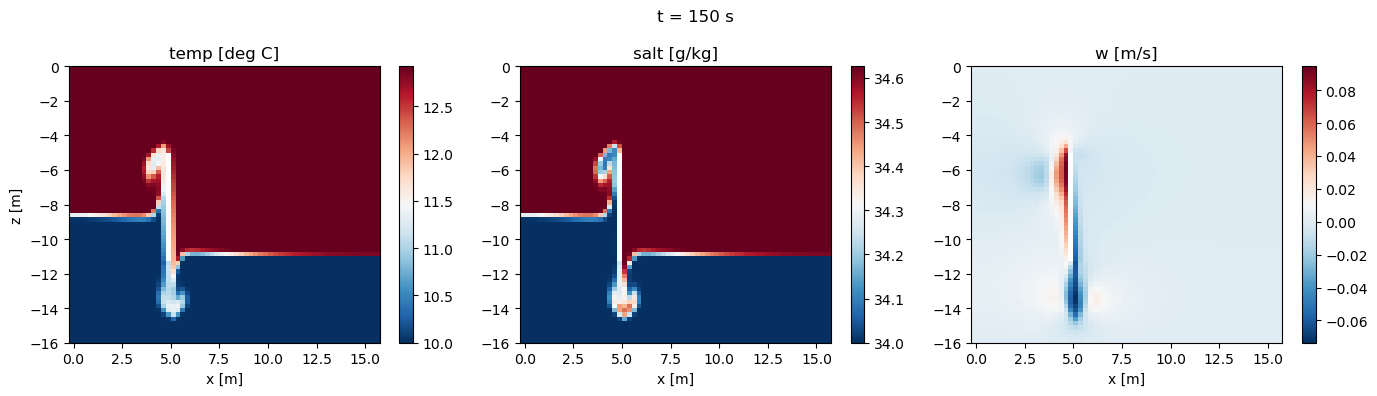

KeyboardInterrupt: 

In [6]:
A, B, C = 1., 0., 0.                 # Adams-Bashforth weights, forward Euler at the start
tau, taum1, taum2 = 2, 1, 0          # pointers to the time levels
for n in range(nsteps):
    M.time_step_implicit_pressure(A, B, C, tau, taum1, taum2)
    if n % plot_every == 0: plot(n*dt)
    tau, taum1, taum2 = (tau+1) % 3, (taum1+1) % 3, (taum2+1) % 3
    A, B, C = (1.5, -0.5, 0.) if n == 0 else (23./12, -16./12, 5./12)

In [ ]:
plot(nsteps*dt)